# Lia · Data Science & Statistical Computing
**Global Solution FIAP 2026.2 · CitizenTech Lia**

A Lia é uma assistente de IA por voz que devolve autonomia digital a quem tem pouca prática com o celular ou com a leitura, principalmente pessoas idosas.
Este notebook usa dados públicos para responder **quem a Lia deve atender primeiro e onde**.

## 1. Contexto e perguntas
1. **Analfabetismo por idade:** quanto o analfabetismo cresce com a idade, e quanto caiu de 2010 para 2022?
2. **Exclusão digital:** como o uso da Internet e de serviços de governo pela Internet cai com a idade e a escolaridade?
3. **Onde:** quais estados têm o maior analfabetismo, e quanto cada região se afasta da média do Brasil?
4. **Prioridade:** qual grupo a Lia deve atender primeiro?

Fontes (detalhes em `dados/FONTES.md`): IBGE, Censo Demográfico 2022 (Alfabetização); Cetic.br, TIC Domicílios 2024.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.8), "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
LARANJA, CINZA, ESCURO = "#FF6D00", "#B0B0B0", "#202124"

uf = pd.read_csv("dados/censo2022_alfabetizacao_uf.csv")
idade = pd.read_csv("dados/censo2022_analfabetismo_idade.csv")
tic = pd.read_csv("dados/tic2024_individuos.csv")
print(uf.shape, idade.shape, tic.shape)

(27, 4) (11, 5) (55, 6)


## 2. Base e preparação
Conferência de tipos, faltantes, faixas válidas e cobertura (27 UFs). A taxa de analfabetismo é o complemento da taxa de alfabetização.

In [2]:
for nome, df in {"uf": uf, "idade": idade, "tic": tic}.items():
    print(nome, "| faltantes:", int(df.isna().sum().sum()), "| colunas:", list(df.columns))

assert uf["sigla"].nunique() == 27, "precisa ter as 27 UFs"
assert uf["taxa_alfabetizacao_2022"].between(0, 100).all()
assert tic["percentual"].between(0, 100).all()

uf["taxa_analfabetismo_2022"] = (100 - uf["taxa_alfabetizacao_2022"]).round(1)
idade["queda_pp"] = (idade["taxa_analfabetismo_2010"] - idade["taxa_analfabetismo_2022"]).round(1)
idade["queda_pct"] = (100 * idade["queda_pp"] / idade["taxa_analfabetismo_2010"]).round(1)
uf.head()

uf | faltantes: 0 | colunas: ['uf', 'sigla', 'regiao', 'taxa_alfabetizacao_2022']
idade | faltantes: 0 | colunas: ['faixa_etaria', 'idade_inicial', 'taxa_analfabetismo_2010', 'taxa_analfabetismo_2022', 'confirmado_em_texto']
tic | faltantes: 0 | colunas: ['indicador', 'descricao', 'base', 'recorte', 'categoria', 'percentual']


,uf,sigla,regiao,taxa_alfabetizacao_2022,taxa_analfabetismo_2022
0,Rondônia,RO,Norte,93.6,6.4
1,Acre,AC,Norte,87.9,12.1
2,Amazonas,AM,Norte,93.1,6.9
3,Roraima,RR,Norte,93.1,6.9
4,Pará,PA,Norte,91.2,8.8


## 3. Análise descritiva
### 3.1 Analfabetismo por estado (15 anos ou mais, 2022)

In [3]:
BRASIL = 7.0  # taxa oficial do IBGE para o Brasil (93,0% de alfabetização)
x = uf["taxa_analfabetismo_2022"]
resumo = pd.Series({
    "média das UFs": x.mean(), "mediana": x.median(), "desvio padrão": x.std(),
    "mínimo": x.min(), "1º quartil": x.quantile(.25), "3º quartil": x.quantile(.75), "máximo": x.max(),
    "amplitude": x.max() - x.min(), "coef. de variação (%)": 100 * x.std() / x.mean(),
}).round(2)
resumo

média das UFs             8.81
mediana                   6.90
desvio padrão             4.90
mínimo                    2.70
1º quartil                5.45
3º quartil               13.60
máximo                   17.70
amplitude                15.00
coef. de variação (%)    55.60
dtype: float64

In [4]:
ranking = uf.sort_values("taxa_analfabetismo_2022", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking["vezes_a_media_BR"] = (ranking["taxa_analfabetismo_2022"] / BRASIL).round(2)
ranking[["uf", "regiao", "taxa_analfabetismo_2022", "vezes_a_media_BR"]].head(10)

,uf,regiao,taxa_analfabetismo_2022,vezes_a_media_BR
1,Alagoas,Nordeste,17.7,2.53
2,Piauí,Nordeste,17.2,2.46
3,Paraíba,Nordeste,16.0,2.29
4,Maranhão,Nordeste,15.0,2.14
5,Ceará,Nordeste,14.1,2.01
6,Rio Grande do Norte,Nordeste,13.9,1.99
7,Sergipe,Nordeste,13.8,1.97
8,Pernambuco,Nordeste,13.4,1.91
9,Bahia,Nordeste,12.6,1.80
10,Acre,Norte,12.1,1.73


In [5]:
regiao = uf.groupby("regiao")["taxa_analfabetismo_2022"].agg(["mean", "min", "max", "count"]).round(1)
regiao["diferenca_para_BR_pp"] = (regiao["mean"] - BRASIL).round(1)
regiao.sort_values("mean", ascending=False)

,mean,min,max,count,diferenca_para_BR_pp
regiao,,,,,
Nordeste,14.9,12.6,17.7,9,7.9
Norte,8.1,6.4,12.1,7,1.1
Centro-Oeste,4.9,2.8,5.8,4,-2.1
Sudeste,4.4,3.1,5.8,4,-2.6
Sul,3.4,2.7,4.3,3,-3.6


> A média do Nordeste aqui é a **média simples das UFs**. A taxa oficial da região, ponderada pela população, é 14,2% (IBGE).

### 3.2 Analfabetismo por idade (Brasil)

In [6]:
idade[["faixa_etaria", "taxa_analfabetismo_2010", "taxa_analfabetismo_2022", "queda_pp", "queda_pct"]]

,faixa_etaria,taxa_analfabetismo_2010,taxa_analfabetismo_2022,queda_pp,queda_pct
0,15 a 19 anos,2.2,1.5,0.7,31.8
1,20 a 24 anos,2.8,1.5,1.3,46.4
2,25 a 29 anos,4.0,1.7,2.3,57.5
3,30 a 34 anos,5.9,2.2,3.7,62.7
4,35 a 39 anos,7.0,3.2,3.8,54.3
5,40 a 44 anos,9.3,5.0,4.3,46.2
6,45 a 49 anos,10.5,7.0,3.5,33.3
7,50 a 54 anos,12.3,8.8,3.5,28.5
8,55 a 59 anos,15.7,10.7,5.0,31.8
9,60 a 64 anos,20.4,12.4,8.0,39.2


In [7]:
jovem = idade.loc[idade.faixa_etaria == "15 a 19 anos", "taxa_analfabetismo_2022"].item()
idoso = idade.loc[idade.faixa_etaria == "65 anos ou mais", "taxa_analfabetismo_2022"].item()
print(f"65+ tem {idoso / jovem:.1f} vezes mais analfabetismo que 15-19 anos ({idoso}% contra {jovem}%).")
print(f"Em 65+, 1 em cada {round(100 / idoso)} pessoas não sabe ler nem escrever um bilhete simples.")

65+ tem 13.5 vezes mais analfabetismo que 15-19 anos (20.3% contra 1.5%).
Em 65+, 1 em cada 5 pessoas não sabe ler nem escrever um bilhete simples.


### 3.3 Exclusão digital por idade e escolaridade (TIC Domicílios 2024)
`C2A` = usa Internet (base: toda a população de 10 anos ou mais). `G1` = usou governo eletrônico nos últimos 12 meses (base: só quem usa Internet, 16 anos ou mais).

Multiplicando os dois, temos uma **estimativa** de quantas pessoas de cada grupo usam serviço público pela Internet. É aproximada, porque supõe que as duas pesquisas descrevem o mesmo grupo.

In [8]:
def tabela(recorte):
    t = tic[(tic.recorte == recorte) & tic.indicador.isin(["C2A", "G1"])].pivot(index="categoria", columns="indicador", values="percentual")
    t = t.dropna()
    t["usa_gov_digital_estimado"] = (t["C2A"] * t["G1"] / 100).round(0)
    return t

por_idade = tabela("Faixa etária").reindex(["De 16 a 24 anos", "De 25 a 34 anos", "De 35 a 44 anos", "De 45 a 59 anos", "De 60 anos ou mais"])
por_idade

indicador,C2A,G1,usa_gov_digital_estimado
categoria,,,
De 16 a 24 anos,98.0,66.0,65.0
De 25 a 34 anos,98.0,70.0,69.0
De 35 a 44 anos,96.0,65.0,62.0
De 45 a 59 anos,88.0,59.0,52.0
De 60 anos ou mais,63.0,38.0,24.0


In [9]:
por_instrucao = tabela("Grau de instrução").reindex(["Analfabeto/Educação Infantil", "Fundamental", "Médio", "Superior"])
por_instrucao

indicador,C2A,G1,usa_gov_digital_estimado
categoria,,,
Analfabeto/Educação Infantil,40,10,4.0
Fundamental,79,39,31.0
Médio,96,63,60.0
Superior,99,83,82.0


In [10]:
i60 = por_idade.loc["De 60 anos ou mais", "usa_gov_digital_estimado"]
i25 = por_idade.loc["De 25 a 34 anos", "usa_gov_digital_estimado"]
anal = por_instrucao.loc["Analfabeto/Educação Infantil", "usa_gov_digital_estimado"]
print(f"60+: cerca de {i60:.0f}% usa serviço público pela Internet (25-34 anos: {i25:.0f}%). Ou seja, 3 em cada 4 idosos estão fora.")
print(f"Analfabetos: cerca de {anal:.0f}% — o grupo mais excluído.")
saude = tic[(tic.indicador == "G2A_saude_online") & (tic.categoria == "De 60 anos ou mais")]["percentual"].item()
print(f"Mesmo entre idosos que usam Internet, só {saude}% conseguiram resolver um serviço de saúde todo online.")

60+: cerca de 24% usa serviço público pela Internet (25-34 anos: 69%). Ou seja, 3 em cada 4 idosos estão fora.
Analfabetos: cerca de 4% — o grupo mais excluído.
Mesmo entre idosos que usam Internet, só 6% conseguiram resolver um serviço de saúde todo online.


## 4. Visualizações

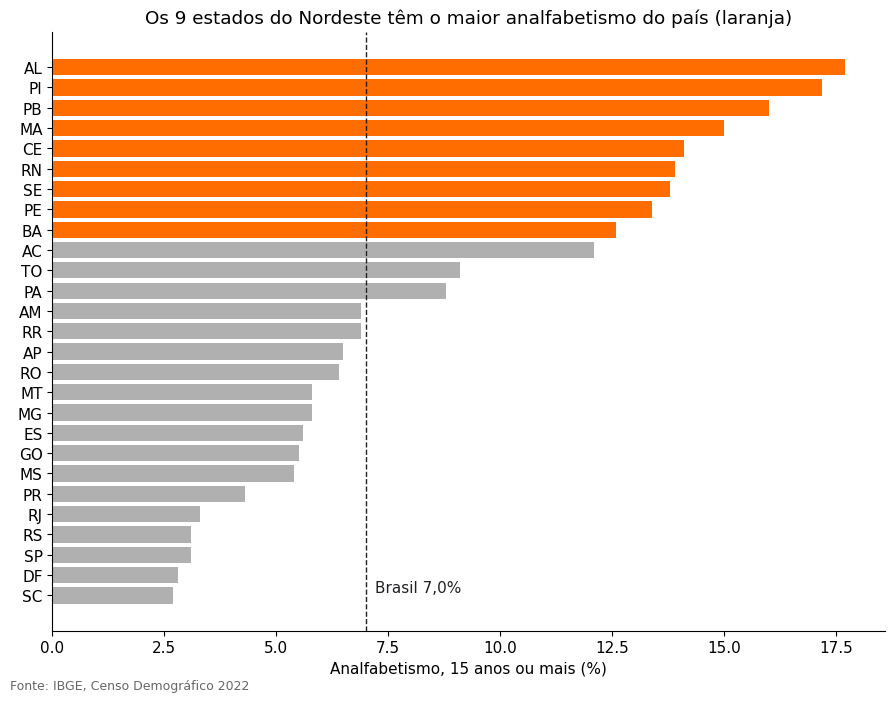

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))
r = uf.sort_values("taxa_analfabetismo_2022")
cores = [LARANJA if g == "Nordeste" else CINZA for g in r["regiao"]]
ax.barh(r["sigla"], r["taxa_analfabetismo_2022"], color=cores)
ax.axvline(BRASIL, color=ESCURO, ls="--", lw=1)
ax.text(BRASIL + .2, 0, "Brasil 7,0%", va="bottom", color=ESCURO)
ax.set_xlabel("Analfabetismo, 15 anos ou mais (%)")
ax.set_title("Os 9 estados do Nordeste têm o maior analfabetismo do país (laranja)")
fig.text(0.01, 0.005, "Fonte: IBGE, Censo Demográfico 2022", fontsize=9, color="#666")
plt.tight_layout(); plt.show()

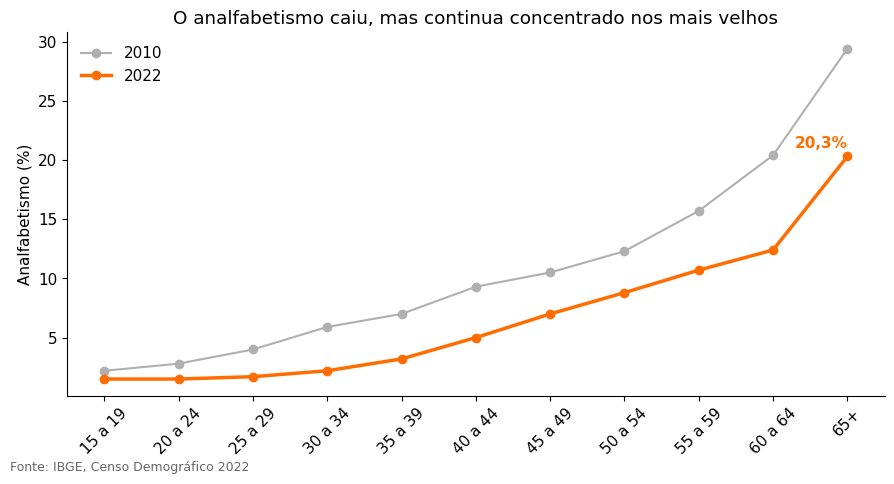

In [12]:
fig, ax = plt.subplots()
ax.plot(idade["idade_inicial"], idade["taxa_analfabetismo_2010"], marker="o", color=CINZA, label="2010")
ax.plot(idade["idade_inicial"], idade["taxa_analfabetismo_2022"], marker="o", color=LARANJA, lw=2.5, label="2022")
ax.set_xticks(idade["idade_inicial"], idade["faixa_etaria"].str.replace(" anos", "").str.replace(" ou mais", "+"), rotation=45)
ax.set_ylabel("Analfabetismo (%)")
ax.set_title("O analfabetismo caiu, mas continua concentrado nos mais velhos")
ax.annotate("20,3%", (65, 20.3), textcoords="offset points", xytext=(-38, 6), color=LARANJA, weight="bold")
ax.legend(frameon=False)
fig.text(0.01, 0.005, "Fonte: IBGE, Censo Demográfico 2022", fontsize=9, color="#666")
plt.tight_layout(); plt.show()

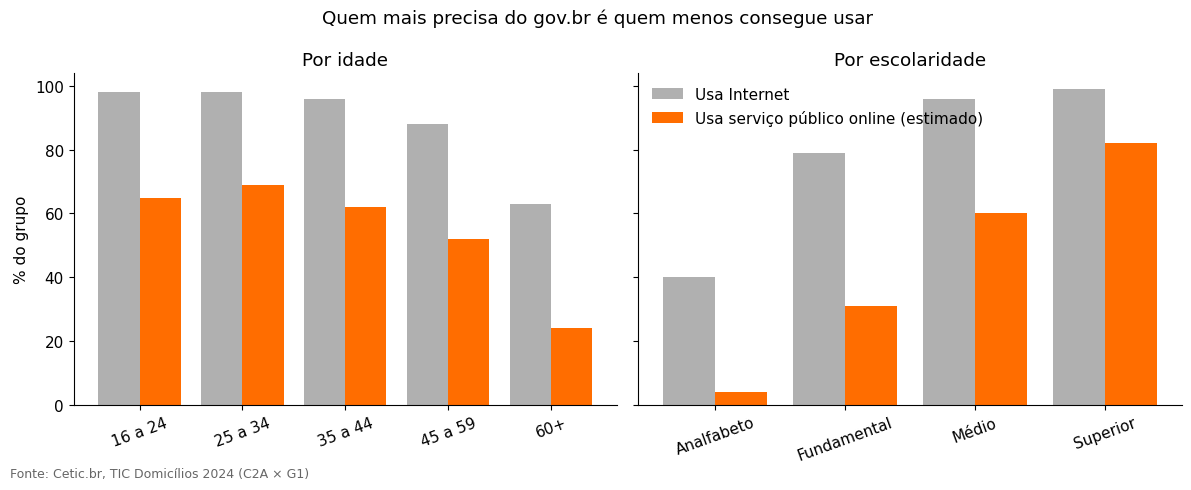

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, t, titulo in [(axs[0], por_idade, "Por idade"), (axs[1], por_instrucao, "Por escolaridade")]:
    rot = [c.replace("De ", "").replace(" anos", "").replace(" ou mais", "+").replace("/Educação Infantil", "") for c in t.index]
    pos = range(len(t))
    ax.bar([p - .2 for p in pos], t["C2A"], width=.4, color=CINZA, label="Usa Internet")
    ax.bar([p + .2 for p in pos], t["usa_gov_digital_estimado"], width=.4, color=LARANJA, label="Usa serviço público online (estimado)")
    ax.set_xticks(list(pos), rot, rotation=20)
    ax.set_title(titulo)
axs[0].set_ylabel("% do grupo")
axs[1].legend(frameon=False, loc="upper left")
fig.suptitle("Quem mais precisa do gov.br é quem menos consegue usar")
fig.text(0.01, 0.005, "Fonte: Cetic.br, TIC Domicílios 2024 (C2A × G1)", fontsize=9, color="#666")
plt.tight_layout(); plt.show()

## 5. Cidade da Lia
A ficha pede uma cidade do interior. Quando a equipe escolher, preencha abaixo a taxa do município (IBGE Cidades ou SIDRA, tabela 9543) e rode a célula: ela compara a cidade com o estado e o Brasil.

In [14]:
CIDADE = None          # ex.: "Nome da cidade"
UF_CIDADE = None       # ex.: "BA"
TAXA_ANALF_CIDADE = None  # % de analfabetismo, 15 anos ou mais, Censo 2022

if CIDADE:
    est = uf.loc[uf.sigla == UF_CIDADE, "taxa_analfabetismo_2022"].item()
    print(f"{CIDADE}: {TAXA_ANALF_CIDADE}% | {UF_CIDADE}: {est}% | Brasil: {BRASIL}%")
    print(f"A cidade está {TAXA_ANALF_CIDADE - est:+.1f} p.p. do estado e {TAXA_ANALF_CIDADE / BRASIL:.1f}x a média do Brasil.")
else:
    print("Cidade ainda não escolhida (backlog 1).")

Cidade ainda não escolhida (backlog 1).


## 6. Conclusões
1. **Idade é o fator mais forte.** O analfabetismo de quem tem 65 anos ou mais (20,3%) é cerca de 13 vezes o de quem tem 15 a 19 anos (1,5%). Caiu desde 2010 (29,4%), mas segue alto.
2. **A exclusão digital se soma ao analfabetismo.** 37% das pessoas com 60 anos ou mais não usam Internet, e só 38% das que usam fizeram algum serviço de governo online. Na estimativa, cerca de **1 em cada 4 idosos** usa serviço público pela Internet, contra 7 em cada 10 adultos de 25 a 34 anos.
3. **Escolaridade derruba tudo.** Entre analfabetos, só 40% usam Internet e 10% dessas usam governo eletrônico: algo como **4 em cada 100**.
4. **Onde:** os nove estados do Nordeste lideram o analfabetismo, com Alagoas (17,7%) e Piauí (17,2%) no topo, mais que o dobro da média do Brasil (7%).
5. **Prioridade da Lia:** pessoas com **60 anos ou mais e baixa escolaridade**, em **cidades do interior** (o uso de governo eletrônico na área rural é 43%, contra 63% na urbana). Isso justifica o foco em voz (não exige leitura), o Guia na tela (ensina em vez de fazer por ela) e o canal por ligação (37% dos idosos nem usam Internet).

**Para o pitch:** "1 em cada 5 brasileiros com 65 anos ou mais não sabe ler um bilhete simples (IBGE, 2022). E só 1 em cada 4 idosos usa serviço público pela Internet (Cetic.br, 2024)."

**Limites:** o cruzamento C2A × G1 é uma estimativa; as taxas por UF não são ponderadas por população; e as faixas de idade intermediárias foram lidas de gráfico (ver `dados/FONTES.md`).